In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns
from google.colab import files
uploaded = files.upload()
# Assuming 'well_GL.csv.csv' was uploaded, you can access it like this:
file_name = list(uploaded.keys())[0] # Gets the name of the first uploaded file
df = pd.read_csv(file_name)
print(df.columns)

Saving CarPrice_Assignment.csv to CarPrice_Assignment.csv
Index(['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration',
       'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase',
       'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype',
       'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke',
       'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg',
       'price'],
      dtype='object')


In [2]:
df.head()
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0


In [3]:
# Target variables
y = df['price']

# Feature variables
X = df.drop(columns=['price'])

In [4]:
X

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,201,-1,volvo 145e (sw),gas,std,four,sedan,rwd,front,109.1,...,four,141,mpfi,3.78,3.15,9.5,114,5400,23,28
201,202,-1,volvo 144ea,gas,turbo,four,sedan,rwd,front,109.1,...,four,141,mpfi,3.78,3.15,8.7,160,5300,19,25
202,203,-1,volvo 244dl,gas,std,four,sedan,rwd,front,109.1,...,six,173,mpfi,3.58,2.87,8.8,134,5500,18,23
203,204,-1,volvo 246,diesel,turbo,four,sedan,rwd,front,109.1,...,six,145,idi,3.01,3.40,23.0,106,4800,26,27


In [5]:
y

,price
0,13495.0
1,16500.0
2,16500.0
3,13950.0
4,17450.0
...,...
200,16845.0
201,19045.0
202,21485.0
203,22470.0


In [6]:
X = X.drop(columns=['car_ID'])

In [7]:
from sklearn.model_selection import train_test_split

# Split train set to be 80% and test set 20%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [9]:
X_train_bsw = X_train[["horsepower", "enginesize"]]
X_test_bsw = X_test[["horsepower", "enginesize"]]

In [10]:
from sklearn.impute import SimpleImputer
imputer_bsw = SimpleImputer(strategy='median')

X_train_bsw_imp = imputer_bsw.fit_transform(X_train_bsw)
X_test_bsw_imp = imputer_bsw.transform(X_test_bsw)

In [12]:
from sklearn.tree import DecisionTreeRegressor

model_bsw = DecisionTreeRegressor(max_depth=5, random_state=42)
y_train_bsw = y_train.loc[X_train.index] # Define y_train_bsw using the indices from X_train

# Remove NaN values from y_train_bsw and corresponding rows from X_train_bsw_imp
not_nan_mask_bsw = ~y_train_bsw.isna()
X_train_bsw_imp_cleaned = X_train_bsw_imp[not_nan_mask_bsw]
y_train_bsw_cleaned = y_train_bsw[not_nan_mask_bsw]

model_bsw.fit(X_train_bsw_imp_cleaned, y_train_bsw_cleaned)

DecisionTreeRegressor(max_depth=5, random_state=42)

In [13]:
# Make prediction
predicted = model_bsw.predict(X_test_bsw_imp)
predicted

array([34950.66666667, 16525.05263158, 12913.54545455, 16603.68421053,
       31600.        ,  7297.5       ,  9176.05      ,  7297.5       ,
       16137.5       ,  9208.6       , 16603.68421053,  7297.5       ,
       21780.5       , 10363.375     , 45400.        ,  6381.78947368,
        6381.78947368, 16525.05263158,  9176.05      , 16137.5       ,
        9176.05      , 16525.05263158,  7297.5       ,  6381.78947368,
        6381.78947368, 34950.66666667, 11771.        , 16603.68421053,
        7297.5       , 16603.68421053, 31600.        ,  6381.78947368,
        6381.78947368, 21780.5       ,  9746.9       , 31600.        ,
        9746.9       , 12913.54545455,  7111.1875    , 16525.05263158,
        7297.5       ])

In [14]:
# Evaluating model performance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Remove NaN values from y_test and corresponding predicted values
not_nan_mask_test = ~y_test.isna()
y_test_cleaned = y_test[not_nan_mask_test]
predicted_cleaned = predicted[not_nan_mask_test]

r2 = r2_score(y_test_cleaned, predicted_cleaned)
print(f"r2: {r2}")
mse = mean_squared_error(y_test_cleaned, predicted_cleaned)
print(f"mean squared error: {mse}")
mae = mean_absolute_error(y_test_cleaned, predicted_cleaned)
print(f"mean absolute error: {mae}")

r2: 0.8900315298255218
mean squared error: 8681353.205558019
mean absolute error: 2323.877038219162


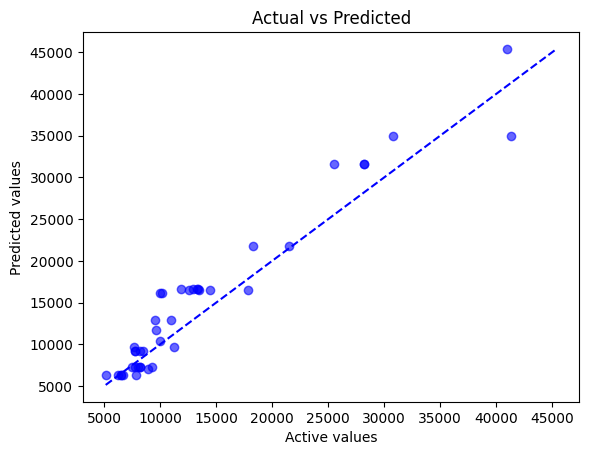

In [15]:
# Plot the actual value vs predict value
import matplotlib.pyplot as plt
import numpy as np

# Ensure both are numpy arrays
y_true = np.array(y_test)  # Corrected from Y_test to y_test
y_pred = np.array(predicted)

plt.scatter(y_true, y_pred, color='blue', alpha = 0.6 )

# Get the limit for the line
min_val = min(y_true.min(), y_pred.min())
max_val = max(y_true.max(), y_pred.max())

# Plot 45-degree referrence line
plt.plot([min_val, max_val], [min_val, max_val], color='blue', linestyle='--')

plt.xlabel('Active values')
plt.ylabel('Predicted values')
plt.title('Actual vs Predicted')
plt.show()